In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

# Config for professional plots
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [12, 6]

# Load Data
processed_path = Path("../data/processed/2023_Bahrain_laps.parquet")
df = pd.read_parquet(processed_path)

print(f"Loaded {len(df)} laps.")
print(f"Drivers: {df['Driver'].unique()}")

Loaded 889 laps.
Drivers: ['VER' 'GAS' 'PER' 'ALO' 'LEC' 'STR' 'SAR' 'MAG' 'DEV' 'TSU' 'ALB' 'ZHO'
 'HUL' 'OCO' 'NOR' 'HAM' 'SAI' 'RUS' 'BOT' 'PIA']


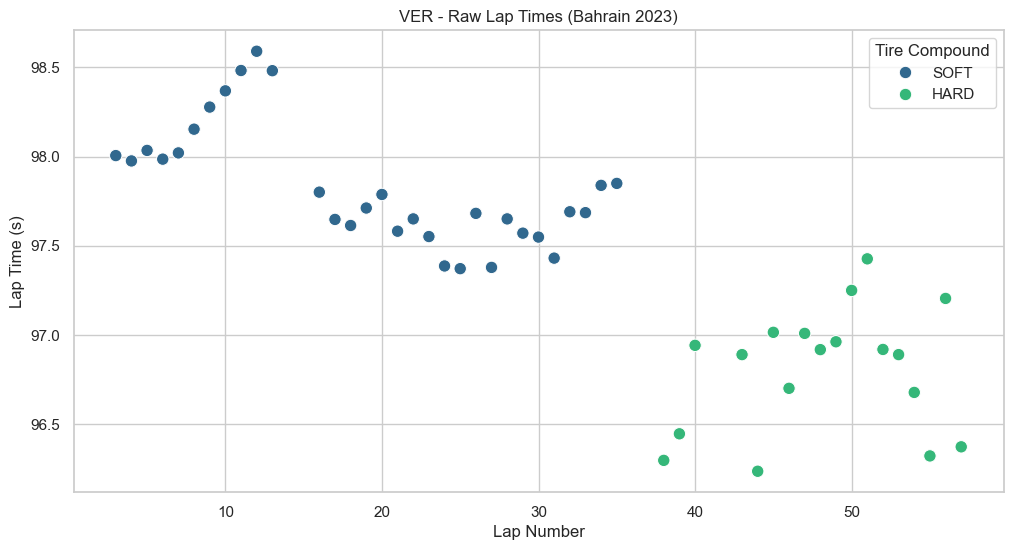

In [2]:
# Filter for the Race Winner
driver_code = 'VER'
driver_laps = df[df['Driver'] == driver_code].copy()

# Plot Raw Lap Times
plt.figure(figsize=(12, 6))
sns.scatterplot(data=driver_laps, x='LapNumber', y='LapTime', hue='Compound', palette='viridis', s=80)
plt.title(f"{driver_code} - Raw Lap Times (Bahrain 2023)")
plt.ylabel("Lap Time (s)")
plt.xlabel("Lap Number")
plt.legend(title='Tire Compound')
plt.show()

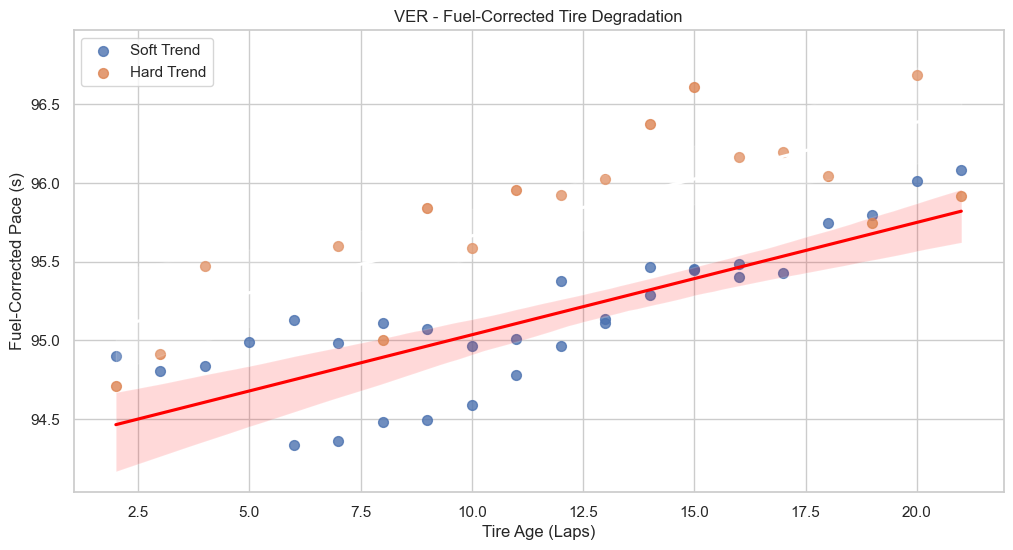

In [3]:
# Physics Constants
FUEL_PENALTY_PER_LAP = 0.06  # Conservative estimate (seconds per kg of fuel effect)
# Note: In reality, this is ~0.03s/kg. Since we burn ~1.7kg/lap, the time gain is ~0.05s per lap.

# Create a correction factor
# We normalize everything to "Empty Tank" pace
# Adjusted Time = Actual Time - (Fuel Mass * Penalty per Kg)
# Since more fuel = slower time, we SUBTRACT the penalty to normalize to 0 fuel.
fuel_penalty_per_kg = 0.035
df['FuelCorrection'] = df['FuelLoad'] * fuel_penalty_per_kg
df['LapTime_Adjusted'] = df['LapTime'] - df['FuelCorrection']

# Let's plot the adjusted pace for VER
driver_laps = df[df['Driver'] == 'VER']

plt.figure(figsize=(12, 6))
sns.regplot(data=driver_laps[driver_laps['Compound']=='SOFT'],
            x='TyreLife', y='LapTime_Adjusted',
            scatter_kws={'s':50}, line_kws={'color':'red'}, label='Soft Trend')

sns.regplot(data=driver_laps[driver_laps['Compound']=='HARD'],
            x='TyreLife', y='LapTime_Adjusted',
            scatter_kws={'s':50}, line_kws={'color':'white'}, label='Hard Trend')

plt.title(f"{driver_code} - Fuel-Corrected Tire Degradation")
plt.ylabel("Fuel-Corrected Pace (s)")
plt.xlabel("Tire Age (Laps)")
plt.legend()
plt.show()

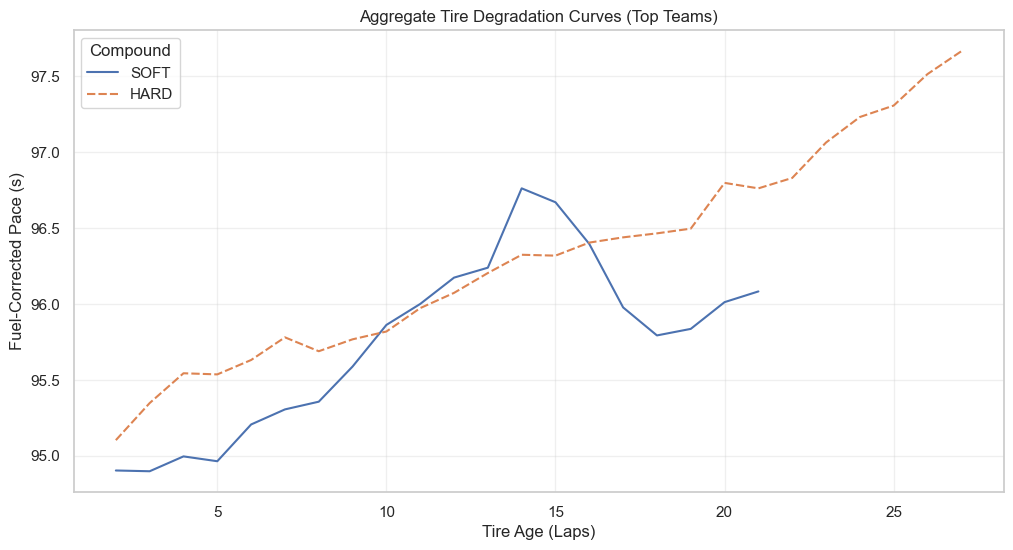

In [4]:
# Filter for top teams to remove backmarker noise
top_teams = ['Red Bull Racing', 'Ferrari', 'Mercedes', 'Aston Martin']
top_laps = df[df['Team'].isin(top_teams)]

plt.figure(figsize=(12, 6))
sns.lineplot(data=top_laps, x='TyreLife', y='LapTime_Adjusted', hue='Compound', style='Compound', errorbar=None)

plt.title("Aggregate Tire Degradation Curves (Top Teams)")
plt.ylabel("Fuel-Corrected Pace (s)")
plt.xlabel("Tire Age (Laps)")
plt.grid(True, alpha=0.3)
plt.show()